In [1]:
import csv
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

PROJECT = Path.cwd().parent
MET = PROJECT / "data" / "metrica"
OUT = PROJECT / "outputs" / "06_metrics"
OUT.mkdir(parents=True, exist_ok=True)

for p in sorted(MET.rglob("*")):
    if p.is_file(): print(f"{p.relative_to(MET)}  ({p.stat().st_size / 1e6:.1f} MB)")

Sample_Game_1_RawEventsData.csv  (0.1 MB)
Sample_Game_1_RawTrackingData_Away_Team.csv  (32.8 MB)
Sample_Game_1_RawTrackingData_Home_Team.csv  (32.8 MB)
Sample_Game_2_RawEventsData.csv  (0.2 MB)
Sample_Game_2_RawTrackingData_Away_Team.csv  (29.6 MB)
Sample_Game_2_RawTrackingData_Home_Team.csv  (31.9 MB)
Sample_Game_3_events.json  (1.7 MB)
Sample_Game_3_metadata.xml  (0.1 MB)
Sample_Game_3_tracking.txt  (53.4 MB)


In [2]:
def find_file(game, kind):
    hits = list(MET.rglob(f"Sample_Game_{game}_{kind}.csv"))
    if not hits: raise FileNotFoundError(f"Sample_Game_{game}_{kind}.csv not found under {MET}")
    return hits[0]

def read_tracking(game, team):
    path = find_file(game, f"RawTrackingData_{team}_Team")
    with open(path, newline="") as f:
        reader = csv.reader(f)
        next(reader)                                     # row 1: team name
        jerseys = [x for x in next(reader) if x != ""]   # row 2: jersey numbers
        cols = next(reader)                              # row 3: column names
    for i, j in enumerate(jerseys):
        cols[3 + 2 * i] = f"{team}_{j}_x"
        cols[4 + 2 * i] = f"{team}_{j}_y"
    cols[-2], cols[-1] = "ball_x", "ball_y"
    return pd.read_csv(path, names=cols, skiprows=3, index_col="Frame")

GAME = 1
home, away = read_tracking(GAME, "Home"), read_tracking(GAME, "Away")
game = home.join(away.drop(columns=["Period", "Time [s]", "ball_x", "ball_y"]))

PITCH_L, PITCH_W = 105.0, 68.0
xcols = [c for c in game.columns if c.endswith("_x")]
ycols = [c for c in game.columns if c.endswith("_y")]
game[xcols] = (game[xcols] - 0.5) * PITCH_L
game[ycols] = (0.5 - game[ycols]) * PITCH_W             # y up = away from the camera side

home_ids = sorted({c.split("_")[1] for c in game.columns if c.startswith("Home_")}, key=int)
away_ids = sorted({c.split("_")[1] for c in game.columns if c.startswith("Away_")}, key=int)
print("frames:", len(game), "| minutes:", round(len(game) / 25 / 60, 1), "| periods:", game.Period.unique())
print("home players:", home_ids); print("away players:", away_ids)
print("share of missing positions per column (top 8):")
print(game[xcols].isna().mean().sort_values(ascending=False).head(8).round(2).to_string())
print(game[["Period", "Time [s]", "Home_11_x", "Home_11_y", "ball_x", "ball_y"]].iloc[[0, 1, 5000]].round(2))

frames: 145006 | minutes: 96.7 | periods: [1 2]
home players: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14']
away players: ['15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28']
share of missing positions per column (top 8):
Home_14_x    0.84
Away_28_x    0.82
Home_13_x    0.76
Away_27_x    0.74
Away_26_x    0.74
Home_1_x     0.68
ball_x       0.39
Home_12_x    0.32
       Period  Time [s]  Home_11_x  Home_11_y  ball_x  ball_y
Frame                                                        
1           1      0.04     -52.41       1.20   -4.75    7.68
2           1      0.08     -52.40       1.20   -0.37    6.35
5001        1    200.04     -38.62      -2.25     NaN     NaN


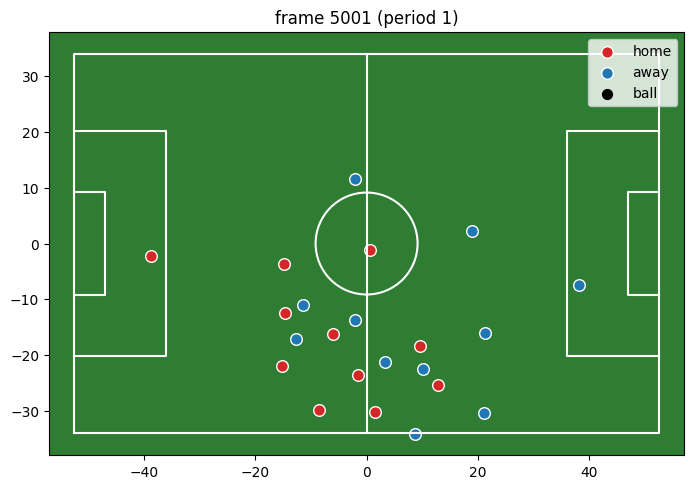

average home x position by period (negative = defends left goal):
Period
1   -2.6
2    7.0


In [3]:
def draw_pitch(ax):
    L, W = PITCH_L / 2, PITCH_W / 2
    ax.plot([-L, L, L, -L, -L], [-W, -W, W, W, -W], "w-", lw=1.5); ax.plot([0, 0], [-W, W], "w-", lw=1.5)
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=False, ec="w", lw=1.5))
    for s in (-1, 1):
        ax.plot([s * L, s * (L - 16.5), s * (L - 16.5), s * L], [-20.16, -20.16, 20.16, 20.16], "w-", lw=1.5)
        ax.plot([s * L, s * (L - 5.5), s * (L - 5.5), s * L], [-9.16, -9.16, 9.16, 9.16], "w-", lw=1.5)
    ax.set_facecolor("#2e7d32"); ax.set_xlim(-57, 57); ax.set_ylim(-38, 38); ax.set_aspect("equal")

fr = game.index[5000]
row = game.loc[fr]
fig, ax = plt.subplots(figsize=(9, 5.5)); draw_pitch(ax)
ax.scatter([row[f"Home_{i}_x"] for i in home_ids], [row[f"Home_{i}_y"] for i in home_ids], c="tab:red", s=70, edgecolors="w", label="home")
ax.scatter([row[f"Away_{i}_x"] for i in away_ids], [row[f"Away_{i}_y"] for i in away_ids], c="tab:blue", s=70, edgecolors="w", label="away")
ax.scatter(row.ball_x, row.ball_y, c="k", s=50, label="ball"); ax.legend(loc="upper right")
ax.set_title(f"frame {fr} (period {int(row.Period)})"); plt.savefig(OUT / "metrica_frame.png", dpi=130); plt.show()

hx = game[[f"Home_{i}_x" for i in home_ids]]
print("average home x position by period (negative = defends left goal):")
print(hx.groupby(game.Period).mean().mean(axis=1).round(1).to_string())

In [4]:
events = pd.read_csv(find_file(GAME, "RawEventsData"))
print(events.shape); print(events.columns.tolist())
print(events.Type.value_counts().to_string())
print(events.head(3).to_string())

(1745, 14)
['Team', 'Type', 'Subtype', 'Period', 'Start Frame', 'Start Time [s]', 'End Frame', 'End Time [s]', 'From', 'To', 'Start X', 'Start Y', 'End X', 'End Y']
Type
PASS              799
RECOVERY          278
BALL LOST         257
CHALLENGE         233
SET PIECE          77
BALL OUT           51
SHOT               24
FAULT RECEIVED     22
CARD                4
   Team       Type   Subtype  Period  Start Frame  Start Time [s]  End Frame  End Time [s]      From        To  Start X  Start Y  End X  End Y
0  Away  SET PIECE  KICK OFF       1            1            0.04          0          0.00  Player19       NaN      NaN      NaN    NaN    NaN
1  Away       PASS       NaN       1            1            0.04          3          0.12  Player19  Player21     0.45     0.39   0.55   0.43
2  Away       PASS       NaN       1            3            0.12         17          0.68  Player21  Player15     0.55     0.43   0.58   0.21


In [5]:
FPS = 25
flip = game.Period == 2
game.loc[flip, xcols] *= -1          # rotate period 2 by 180 degrees so Home always attacks right
game.loc[flip, ycols] *= -1

first10 = game[game.Period == 1].iloc[: FPS * 60 * 10]
hm = {i: first10[f"Home_{i}_x"].mean() for i in home_ids}
am = {i: first10[f"Away_{i}_x"].mean() for i in away_ids}
HOME_GK = min((k for k in hm if pd.notna(hm[k])), key=hm.get)     # Home defends the left goal
AWAY_GK = max((k for k in am if pd.notna(am[k])), key=am.get)     # Away defends the right goal
print("goalkeepers: Home", HOME_GK, "| Away", AWAY_GK)
print("Home goalkeeper mean x by period (should now be about -45 in both):")
print(game.groupby("Period")[f"Home_{HOME_GK}_x"].mean().round(1).to_string())

goalkeepers: Home 11 | Away 25
Home goalkeeper mean x by period (should now be about -45 in both):
Period
1   -39.4
2   -42.6


     player  team  minutes  distance_km  top_speed_kmh  walk <2 m/s  jog 2-4  run 4-5.5  high-speed 5.5-7  sprint >7  sprints
0   Away_18  Away     96.7        11.26           29.1         3620     4853       1925               608        255       11
1   Away_21  Away     96.7        10.98           27.5         3598     4568       2078               581        153        7
2   Away_17  Away     96.7        10.96           27.2         4268     3796       2087               669        136        7
3   Away_20  Away     96.7        10.32           28.0         3507     4408       1590               629        182        9
4   Away_23  Away     96.7        10.31           31.2         4060     4019       1309               496        419       18
5   Away_16  Away     96.7         9.93           28.4         4132     3908       1276               445        164        9
6   Away_19  Away     79.6         9.92           26.3         2844     4126       2313               546         86  

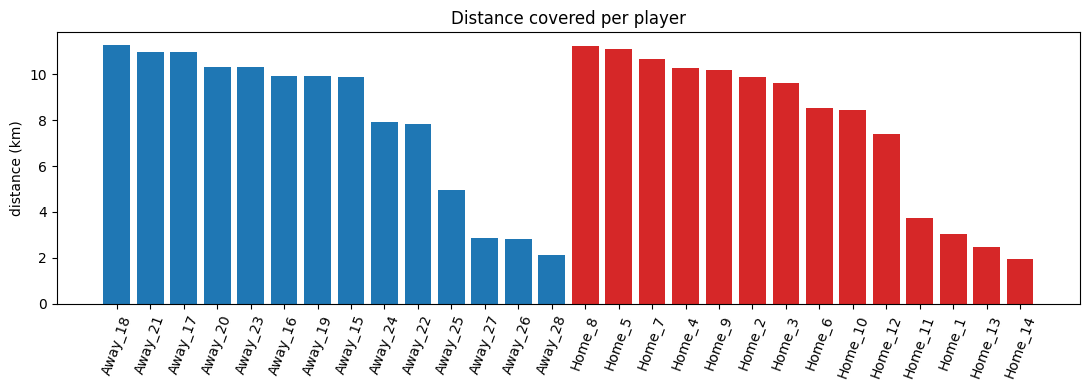

In [11]:
DT = 1 / FPS
MAX_SPEED = 10.5                       # m/s = 37.8 km/h; anything faster is a tracking glitch

def speed_of(team, ids):
    out = {}
    for i in ids:
        # median over 5 frames removes one/two-frame position spikes, then a mean smooths the rest
        xs = game[f"{team}_{i}_x"].rolling(5, center=True, min_periods=3).median().rolling(5, center=True, min_periods=3).mean()
        ys = game[f"{team}_{i}_y"].rolling(5, center=True, min_periods=3).median().rolling(5, center=True, min_periods=3).mean()
        v = np.hypot(xs.diff(), ys.diff()) / DT
        out[f"{team}_{i}"] = v.where(v < MAX_SPEED)
    return pd.DataFrame(out)

speed = pd.concat([speed_of("Home", home_ids), speed_of("Away", away_ids)], axis=1)

ZONES = [("walk <2 m/s", 0, 2), ("jog 2-4", 2, 4), ("run 4-5.5", 4, 5.5), ("high-speed 5.5-7", 5.5, 7), ("sprint >7", 7, 99)]
rows = []
for col in speed.columns:
    v = speed[col].dropna()
    if len(v) < FPS * 60: continue
    r = dict(player=col, team=col.split("_")[0],
             minutes=round(game[col + "_x"].notna().sum() / FPS / 60, 1),
             distance_km=round(v.sum() * DT / 1000, 2), top_speed_kmh=round(v.quantile(0.999) * 3.6, 1))
    for name, lo, hi in ZONES:
        r[name] = int(v[(v >= lo) & (v < hi)].sum() * DT)
    s = (speed[col] > 7).astype(int)
    runs = s.groupby((s != s.shift()).cumsum()).agg(["first", "size"])
    r["sprints"] = int(((runs["first"] == 1) & (runs["size"] >= FPS)).sum())
    rows.append(r)

players = pd.DataFrame(rows).sort_values(["team", "distance_km"], ascending=[True, False]).reset_index(drop=True)
players.to_csv(OUT / "player_workload.csv", index=False)
print(players.to_string())

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(players.player, players.distance_km, color=["tab:red" if t == "Home" else "tab:blue" for t in players.team])
ax.set_ylabel("distance (km)"); ax.set_title("Distance covered per player"); plt.xticks(rotation=70)
plt.tight_layout(); plt.savefig(OUT / "distance_per_player.png", dpi=130); plt.show()

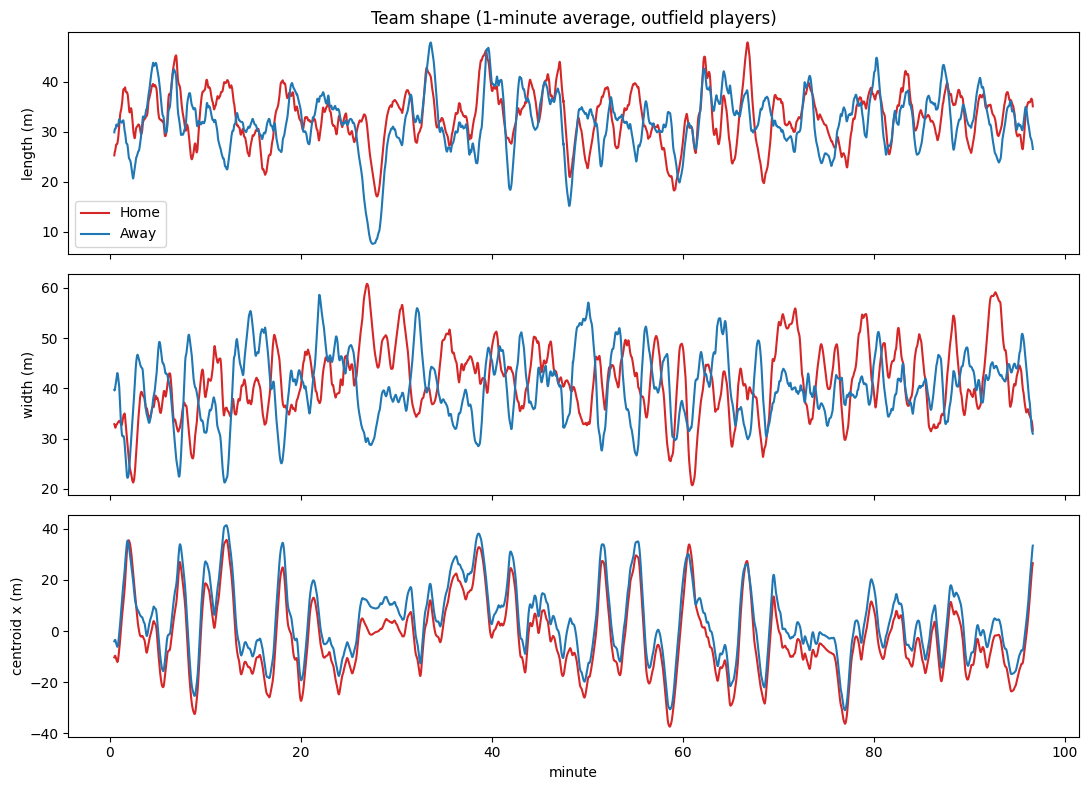

Home
           n  length  width   cx
Period                          
1       10.0    33.6   41.5  0.9
2       10.0    32.3   41.4 -5.3
Away
           n  length  width   cx
Period                          
1       10.0    31.5   39.9  7.6
2       10.0    32.2   40.9  0.8


In [9]:
def team_shape(team, ids, gk):
    outf = [i for i in ids if i != gk]
    X = game[[f"{team}_{i}_x" for i in outf]]; Y = game[[f"{team}_{i}_y" for i in outf]]
    sh = pd.DataFrame({"n": X.notna().sum(axis=1), "cx": X.mean(axis=1), "cy": Y.mean(axis=1),
                       "length": X.max(axis=1) - X.min(axis=1), "width": Y.max(axis=1) - Y.min(axis=1)})
    return sh[sh.n >= 8]                                  # need at least 8 outfielders tracked

shapes = {"Home": team_shape("Home", home_ids, HOME_GK), "Away": team_shape("Away", away_ids, AWAY_GK)}

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for team, c in [("Home", "tab:red"), ("Away", "tab:blue")]:
    sh = shapes[team]
    for a, col, lab in zip(ax, ["length", "width", "cx"], ["length (m)", "width (m)", "centroid x (m)"]):
        a.plot(sh.index / FPS / 60, sh[col].rolling(FPS * 60, min_periods=FPS * 30).mean(), c=c, label=team)
        a.set_ylabel(lab)
ax[0].legend(); ax[-1].set_xlabel("minute"); ax[0].set_title("Team shape (1-minute average, outfield players)")
plt.tight_layout(); plt.savefig(OUT / "team_shape_over_time.png", dpi=130); plt.show()

for team in shapes:
    t = shapes[team].join(game["Period"])
    print(team); print(t.groupby("Period")[["n", "length", "width", "cx"]].mean().round(1).to_string())
    shapes[team].to_csv(OUT / f"shape_{team.lower()}.csv")

In [10]:
t0, t1 = 25.5 * 60, 29 * 60
print(events[(events["Start Time [s]"] >= t0) & (events["Start Time [s]"] <= t1)]
      [["Team", "Type", "Subtype", "Period", "Start Time [s]", "From", "To"]].to_string())

s = shapes["Away"]["length"].rolling(FPS * 60, min_periods=FPS * 30).mean()
print("Away shortest 1-min average length at minute", round(s.idxmin() / FPS / 60, 1), ":", round(s.min(), 1), "m")
print("players tracked at that moment:", int(shapes["Away"].loc[s.idxmin(), "n"]))

     Team            Type            Subtype  Period  Start Time [s]      From        To
508  Away            PASS                NaN       1         1531.00  Player21  Player19
509  Home       CHALLENGE         TACKLE-WON       1         1532.52   Player6       NaN
510  Home        RECOVERY              THEFT       1         1532.52   Player6       NaN
511  Away       CHALLENGE        TACKLE-LOST       1         1532.68  Player19       NaN
512  Away       BALL LOST              THEFT       1         1532.68  Player19       NaN
513  Home            PASS                NaN       1         1532.96   Player6   Player9
514  Home            PASS                NaN       1         1534.92   Player9   Player7
515  Home            PASS                NaN       1         1536.76   Player7   Player1
516  Away        RECOVERY       INTERCEPTION       1         1538.28  Player22       NaN
517  Away       CHALLENGE  TACKLE-FAULT-LOST       1         1538.28  Player22       NaN
518  Home       CHALL

In [12]:
ev = events.sort_values("Start Frame")
marks = []
for t, st, f in zip(ev.Type, ev.Subtype, ev["Start Frame"]):
    if t == "SET PIECE":
        marks.append((int(f), True))
    elif t in ("BALL OUT", "FAULT RECEIVED") or (t == "SHOT" and "GOAL" in str(st).upper()):
        marks.append((int(f), False))

in_play = pd.Series(False, index=game.index)
for (f, s), nxt in zip(marks, marks[1:] + [(int(game.index.max()) + 1, None)]):
    in_play.loc[f:nxt[0] - 1] = s
in_play.to_csv(OUT / "in_play.csv")

total_min = len(game) / FPS / 60
print(f"ball in play: {in_play.mean() * 100:.0f}% of the recorded time = {in_play.sum() / FPS / 60:.1f} of {total_min:.1f} min")
print(in_play.groupby(game.Period).mean().mul(100).round(0).rename("in play (%)").to_string())

# is the dip at minute 27 gone when only play time is counted?
for team in shapes:
    sh = shapes[team].join(in_play.rename("in_play")).join(game["Period"])
    print(f"\n{team}: shape in play vs dead ball")
    print(sh.groupby("in_play")[["length", "width", "cx"]].mean().round(1).to_string())
    play_len = sh[sh.in_play].length.rolling(FPS * 60, min_periods=FPS * 30).mean()
    print("shortest 1-min average length while in play:", round(play_len.min(), 1), "m")

ball in play: 58% of the recorded time = 55.8 of 96.7 min
Period
1    57.0
2    59.0

Home: shape in play vs dead ball
         length  width   cx
in_play                    
False      32.1   41.0 -0.2
True       33.6   41.8 -3.8
shortest 1-min average length while in play: 24.7 m

Away: shape in play vs dead ball
         length  width   cx
in_play                    
False      28.6   36.4  6.3
True       34.3   43.3  2.6
shortest 1-min average length while in play: 26.4 m


## Findings (Metrica Sample Game 1: 145,006 frames at 25 Hz = 96.7 min, 14 + 14 players)
- Positions were converted from 0-1 fractions to metres (105 x 68 m pitch, origin at the centre spot) and
  the second half was rotated 180 degrees so Home always attacks to the right.
- Speed cleaning matters: a first version (5-frame mean, 12 m/s cap) still produced "top speeds" of 41-43 km/h.
  Median filter + mean smoothing and a 10.5 m/s cap removed them. Top speed is reported as the 99.9th percentile
  (24-31 km/h outfield), which underestimates the true peak.
- Full-match outfield players covered 9.6-11.3 km; goalkeepers 3.8 km (Home) and 4.9 km (Away).
- Ball in play: 55.8 of 96.7 recorded minutes (58%), derived from the events file
  (restart = SET PIECE; stop = BALL OUT, FAULT RECEIVED, or a goal).
- A collapse of team length to 8 m at minute 27 was a real 160-second injury stoppage; with dead time removed
  the shortest 1-minute team length is 25-26 m.
- Team shape while the ball is in play (outfield players): Home 33.6 m long x 41.8 m wide, Away 34.3 x 43.3 m.
- Limits: one match; the in-play flag is approximate (event timings); ball position is missing in 39% of frames.